# 🏠 Home Insurance Claim Prediction

Data Mining project — predict whether a home insurance policy will lead to a **claim** (`claim` = 1) from the characteristics of the building and of the contract.

**Pipeline:** exploration → cleaning & imputation → encoding → outliers & scaling → target encoding → association rules (feature engineering) → Decision Tree → Random Forest (+ RandomizedSearchCV) → evaluation.

> The dataset (`insurance.xlsx`, sheets `train` and `test`) is not versioned. Place it in `data/insurance.xlsx` before running the notebook.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder ,OrdinalEncoder, KBinsDiscretizer , QuantileTransformer, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.tree import DecisionTreeClassifier , plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve,f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_predict

import warnings
warnings.filterwarnings('ignore')

## 1. Loading the data

In [3]:
DATA_PATH = "data/insurance.xlsx"  # place the dataset here (not versioned)

df_train = pd.read_excel(DATA_PATH, sheet_name='train')
print(df_train.shape)
df_train

(5014, 13)


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,H13501,2012.0,1.0,1.0,N/V,V,U,1240.0,Wood-framed,without,NaN,75117,non
3,H14962,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,NaN,62916,non
4,H17755,2013.0,1.0,1.0,V/N,O,R,4984.0,Non-combustible,4,NaN,31149,oui
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5009,H13682,2013.0,1.0,0.0,N/V,V,U,550.0,Ordinary,without,NaN,33063,oui
5010,H18342,2012.0,0.5,0.0,V/N,O,R,1000.0,Fire-resistive,4,NaN,13004,non
5011,H16892,2015.0,1.0,1.0,V/N,O,R,480.0,Ordinary,3,NaN,94059,non
5012,H18805,2012.0,0.5,0.0,V/N,O,R,536.0,Fire-resistive,4,NaN,74243,non


In [4]:
df_test = pd.read_excel(DATA_PATH, sheet_name='test')
print(df_test.shape)
df_test

(2147, 13)


,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
0,H3733,2013,1.0,0,V/V,V,U,3760.0,Fire-resistive,without,0.72,43157,oui
1,H16909,2015,1.0,0,V/N,O,R,1452.0,Fire-resistive,5,0.45,58194,non
2,H16867,2013,1.0,1,V/N,O,R,1944.0,Ordinary,6,0.79,92050,oui
3,H14813,2015,1.0,0,N/V,V,U,2270.0,Non-combustible,without,0.66,13209,oui
4,H3728,2016,0.5,0,V/N,O,R,2976.0,Fire-resistive,9,0.18,5177,non
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,H19924,2016,0.5,1,V/N,O,R,862.0,Wood-framed,2,0.71,6159,non
2143,H17249,2012,1.0,0,V/V,V,U,NaN,Non-combustible,without,0.75,NaN,non
2144,H18804,2014,1.0,0,V/N,O,R,730.0,Non-combustible,3,0.35,69027,non
2145,H12650,2014,1.0,1,N/V,V,U,568.0,Non-combustible,without,0.84,69091,oui


## 2. First exploration
Types, descriptive statistics and missing values.

In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5014 entries, 0 to 5013
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   policy_id               5012 non-null   object 
 1   year                    5012 non-null   float64
 2   coverage_period         5012 non-null   float64
 3   is_residential          5012 non-null   float64
 4   is_finished_and_fenced  5012 non-null   object 
 5   has_garden              5008 non-null   object 
 6   locality                5012 non-null   object 
 7   area_m2                 4935 non-null   float64
 8   structure_type          5012 non-null   object 
 9   window_count            5012 non-null   object 
 10  risk_score              0 non-null      float64
 11  Geo_Code                4939 non-null   object 
 12  claim                   5012 non-null   object 
dtypes: float64(5), object(8)
memory usage: 509.4+ KB


In [6]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2147 entries, 0 to 2146
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   policy_id               2147 non-null   object 
 1   year                    2147 non-null   int64  
 2   coverage_period         2147 non-null   float64
 3   is_residential          2147 non-null   int64  
 4   is_finished_and_fenced  2147 non-null   object 
 5   has_garden              2144 non-null   object 
 6   locality                2147 non-null   object 
 7   area_m2                 2118 non-null   float64
 8   structure_type          2147 non-null   object 
 9   window_count            2147 non-null   object 
 10  risk_score              2147 non-null   float64
 11  Geo_Code                2118 non-null   object 
 12  claim                   2147 non-null   object 
dtypes: float64(3), int64(2), object(8)
memory usage: 218.2+ KB


In [7]:
df_train.describe(include="all")

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
count,5012,5012.000000,5012.000000,5012.000000,5012,5008,5012,4935.000000,5012,5012,0.0,4939,5012
unique,5012,NaN,NaN,NaN,4,2,2,NaN,4,11,NaN,1115,2
top,H13501,NaN,NaN,NaN,V/N,O,R,NaN,Non-combustible,without,NaN,6088,non
freq,1,NaN,NaN,NaN,2530,2532,2537,NaN,2310,2476,NaN,102,3886
mean,NaN,2013.660215,0.869713,0.301077,NaN,NaN,NaN,1876.898683,NaN,NaN,NaN,NaN,NaN
std,NaN,1.383134,0.219496,0.458772,NaN,NaN,NaN,2267.277397,NaN,NaN,NaN,NaN,NaN
min,NaN,2012.000000,0.500000,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,2012.000000,0.500000,0.000000,NaN,NaN,NaN,520.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,2013.000000,1.000000,0.000000,NaN,NaN,NaN,1067.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,2015.000000,1.000000,1.000000,NaN,NaN,NaN,2280.000000,NaN,NaN,NaN,NaN,NaN


In [8]:
df_test.describe(include="all")

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
count,2147,2147.000000,2147.000000,2147.000000,2147,2144,2147,2118.000000,2147,2147,2147.000000,2118,2147
unique,2147,NaN,NaN,NaN,4,2,2,NaN,4,11,NaN,714,2
top,H3733,NaN,NaN,NaN,V/N,V,U,NaN,Non-combustible,without,NaN,6088,non
freq,1,NaN,NaN,NaN,1071,1074,1074,NaN,995,1074,NaN,41,1639
mean,NaN,2013.691197,0.876805,0.315789,NaN,NaN,NaN,1899.700189,NaN,NaN,0.500186,NaN,NaN
std,NaN,1.385631,0.215504,0.464938,NaN,NaN,NaN,2304.300053,NaN,NaN,0.232729,NaN,NaN
min,NaN,2012.000000,0.500000,0.000000,NaN,NaN,NaN,10.000000,NaN,NaN,0.100000,NaN,NaN
25%,NaN,2012.000000,1.000000,0.000000,NaN,NaN,NaN,535.500000,NaN,NaN,0.290000,NaN,NaN
50%,NaN,2013.000000,1.000000,0.000000,NaN,NaN,NaN,1100.000000,NaN,NaN,0.490000,NaN,NaN
75%,NaN,2015.000000,1.000000,1.000000,NaN,NaN,NaN,2300.000000,NaN,NaN,0.710000,NaN,NaN


In [9]:
print("Nombre total de valeurs manquantes:", df_train.isnull().sum().sum())
print("\nValeurs manquantes par attribut:")
print(df_train.isnull().sum())

Nombre total de valeurs manquantes: 5192

Valeurs manquantes par attribut:
policy_id                    2
year                         2
coverage_period              2
is_residential               2
is_finished_and_fenced       2
has_garden                   6
locality                     2
area_m2                     79
structure_type               2
window_count                 2
risk_score                5014
Geo_Code                    75
claim                        2
dtype: int64


In [10]:
print("Nombre total de valeurs manquantes:", df_test.isnull().sum().sum())
print("\nValeurs manquantes par attribut:")
print(df_test.isnull().sum())

Nombre total de valeurs manquantes: 61

Valeurs manquantes par attribut:
policy_id                  0
year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 3
locality                   0
area_m2                   29
structure_type             0
window_count               0
risk_score                 0
Geo_Code                  29
claim                      0
dtype: int64


## 3. Cleaning
- `risk_score` is entirely empty in the training set → dropped
- fully empty rows and the identifier `policy_id` → dropped

In [11]:
colonnes_null = list(df_train.columns[df_train.isnull().all()])
print(colonnes_null)

['risk_score']


In [12]:
df_train = df_train.dropna(axis=0, how='all',ignore_index=True)
df_train = df_train.dropna(axis=1, how='all')
df_train = df_train.drop(columns=["policy_id"])
df_train

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2012.0,1.0,1.0,N/V,V,U,1240.0,Wood-framed,without,75117,non
1,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,62916,non
2,2013.0,1.0,1.0,V/N,O,R,4984.0,Non-combustible,4,31149,oui
3,2016.0,0.5,0.0,N/V,V,U,600.0,Wood-framed,without,6012,oui
4,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,57631,non
...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,N/V,V,U,550.0,Ordinary,without,33063,oui
5008,2012.0,0.5,0.0,V/N,O,R,1000.0,Fire-resistive,4,13004,non
5009,2015.0,1.0,1.0,V/N,O,R,480.0,Ordinary,3,94059,non
5010,2012.0,0.5,0.0,V/N,O,R,536.0,Fire-resistive,4,74243,non


In [13]:
df_test = df_test.dropna(axis=0, how='all',ignore_index=True)
df_test = df_test.drop(columns=colonnes_null)
df_test = df_test.drop(columns=["policy_id"])
df_test

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2013,1.0,0,V/V,V,U,3760.0,Fire-resistive,without,43157,oui
1,2015,1.0,0,V/N,O,R,1452.0,Fire-resistive,5,58194,non
2,2013,1.0,1,V/N,O,R,1944.0,Ordinary,6,92050,oui
3,2015,1.0,0,N/V,V,U,2270.0,Non-combustible,without,13209,oui
4,2016,0.5,0,V/N,O,R,2976.0,Fire-resistive,9,5177,non
...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,V/N,O,R,862.0,Wood-framed,2,6159,non
2143,2012,1.0,0,V/V,V,U,NaN,Non-combustible,without,NaN,non
2144,2014,1.0,0,V/N,O,R,730.0,Non-combustible,3,69027,non
2145,2014,1.0,1,N/V,V,U,568.0,Non-combustible,without,69091,oui


In [14]:
print("Nombre total de valeurs manquantes(df_train):", df_train.isnull().sum().sum())
print("\nValeurs manquantes par attribut(df_train):")
print(df_train.isnull().sum())

Nombre total de valeurs manquantes(df_train): 154

Valeurs manquantes par attribut(df_train):
year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 4
locality                   0
area_m2                   77
structure_type             0
window_count               0
Geo_Code                  73
claim                      0
dtype: int64


In [15]:
print("Nombre total de valeurs manquantes(df_test):", df_test.isnull().sum().sum())
print("\nValeurs manquantes par attribut(df_test):")
print(df_test.isnull().sum())

Nombre total de valeurs manquantes(df_test): 61

Valeurs manquantes par attribut(df_test):
year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 3
locality                   0
area_m2                   29
structure_type             0
window_count               0
Geo_Code                  29
claim                      0
dtype: int64


## 4. Target encoding (`claim`: non/oui → 0/1)

In [16]:
enc = LabelEncoder()
df_train["claim"]=enc.fit_transform(df_train.loc[:,"claim"])#{"non":0, "oui": 1}
df_train

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2012.0,1.0,1.0,N/V,V,U,1240.0,Wood-framed,without,75117,0
1,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,62916,0
2,2013.0,1.0,1.0,V/N,O,R,4984.0,Non-combustible,4,31149,1
3,2016.0,0.5,0.0,N/V,V,U,600.0,Wood-framed,without,6012,1
4,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,57631,0
...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,N/V,V,U,550.0,Ordinary,without,33063,1
5008,2012.0,0.5,0.0,V/N,O,R,1000.0,Fire-resistive,4,13004,0
5009,2015.0,1.0,1.0,V/N,O,R,480.0,Ordinary,3,94059,0
5010,2012.0,0.5,0.0,V/N,O,R,536.0,Fire-resistive,4,74243,0


In [17]:
df_test["claim"]=enc.transform(df_test.loc[:,"claim"])
df_test

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2013,1.0,0,V/V,V,U,3760.0,Fire-resistive,without,43157,1
1,2015,1.0,0,V/N,O,R,1452.0,Fire-resistive,5,58194,0
2,2013,1.0,1,V/N,O,R,1944.0,Ordinary,6,92050,1
3,2015,1.0,0,N/V,V,U,2270.0,Non-combustible,without,13209,1
4,2016,0.5,0,V/N,O,R,2976.0,Fire-resistive,9,5177,0
...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,V/N,O,R,862.0,Wood-framed,2,6159,0
2143,2012,1.0,0,V/V,V,U,NaN,Non-combustible,without,NaN,0
2144,2014,1.0,0,V/N,O,R,730.0,Non-combustible,3,69027,0
2145,2014,1.0,1,N/V,V,U,568.0,Non-combustible,without,69091,1


## 5. Missing values of `area_m2`
Imputed with the training median (the target is never used, to avoid leakage).

In [18]:
l_num=list(df_train.select_dtypes(exclude="object").columns)
l_discret=list(df_train.select_dtypes(include="object").columns)
print("l_num= ",l_num)
print("l_discret= ",l_discret)

l_num=  ['year', 'coverage_period', 'is_residential', 'area_m2', 'claim']
l_discret=  ['is_finished_and_fenced', 'has_garden', 'locality', 'structure_type', 'window_count', 'Geo_Code']


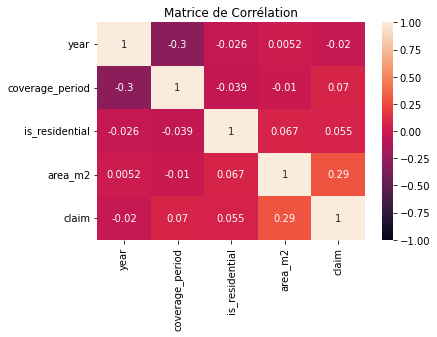

In [19]:
df_corr=df_train.corr(numeric_only=True)
sns.heatmap(df_corr, annot=True,vmin=-1, vmax=1)
plt.title('Matrice de Corrélation')
plt.show()

In [20]:
df=df_corr["area_m2"].drop("area_m2")
cor=df.idxmax()
cor

'claim'

In [21]:
# Impute missing area_m2 with the TRAIN median (the target cannot be used: it is unknown at prediction time)
area_median = df_train['area_m2'].median()
df_train['area_m2'] = df_train['area_m2'].fillna(area_median)
print(df_train["area_m2"].isnull().sum(), area_median)

0 1067.0


In [22]:
df_test['area_m2'] = df_test['area_m2'].fillna(area_median)
print(df_test["area_m2"].isnull().sum())

0


In [23]:
print(df_test[l_num].isnull().sum())

year               0
coverage_period    0
is_residential     0
area_m2            0
claim              0
dtype: int64


## 6. Categorical variables — Cramér's V
Association between categorical variables, used to impute `has_garden` from `locality`.

In [24]:
#ref :: https://www.kaggle.com/code/chrisbss1/cramer-s-v-correlation-matrix
from scipy.stats import chi2_contingency
import numpy as np

def cramers_V(var1,var2) :
  crosstab =np.array(pd.crosstab(var1,var2, rownames=None, colnames=None)) # Cross table building
  stat = chi2_contingency(crosstab)[0] # Keeping of the test statistic of the Chi2 test
  obs = np.sum(crosstab) # Number of observations
  mini = min(crosstab.shape)-1 # Take the minimum value between the columns and the rows of the cross table
  return np.sqrt(stat/(obs*mini))

In [25]:
df_disc = pd.DataFrame()
df_disc[l_discret]=df_train.select_dtypes(include='object')
df_disc

,is_finished_and_fenced,has_garden,locality,structure_type,window_count,Geo_Code
0,N/V,V,U,Wood-framed,without,75117
1,N/V,V,U,Non-combustible,without,62916
2,V/N,O,R,Non-combustible,4,31149
3,N/V,V,U,Wood-framed,without,6012
4,N/V,V,U,Non-combustible,without,57631
...,...,...,...,...,...,...
5007,N/V,V,U,Ordinary,without,33063
5008,V/N,O,R,Fire-resistive,4,13004
5009,V/N,O,R,Ordinary,3,94059
5010,V/N,O,R,Fire-resistive,4,74243


In [26]:
rows= []

for var1 in df_disc:
  col = []
  for var2 in df_disc :
    cramers =cramers_V(df_disc[var1], df_disc[var2]) # Cramer's V test
    col.append(round(cramers,2)) # Keeping of the rounded value of the Cramer's V  
  rows.append(col)
  
cramers_results = np.array(rows)
df = pd.DataFrame(cramers_results, columns = df_disc.columns, index =df_disc.columns)

df

,is_finished_and_fenced,has_garden,locality,structure_type,window_count,Geo_Code
is_finished_and_fenced,1.00,1.00,1.00,0.04,0.58,0.55
has_garden,1.00,1.00,1.00,0.02,1.00,0.59
locality,1.00,1.00,1.00,0.02,1.00,0.59
structure_type,0.04,0.02,0.02,1.00,0.15,0.98
window_count,0.58,1.00,1.00,0.15,1.00,0.52
Geo_Code,0.55,0.59,0.59,0.98,0.52,1.00


In [27]:
for x in l_discret:
    print(x,": ",df_train[x].unique())

is_finished_and_fenced :  ['N/V' 'V/N' 'V/V' 'N/N']
has_garden :  ['V' 'O' nan]
locality :  ['U' 'R']
structure_type :  ['Wood-framed' 'Non-combustible' 'Ordinary' 'Fire-resistive']
window_count :  ['without' '4' '2' '7' '5' '3' '8' '>=10' '6' '1' '9']
Geo_Code :  ['75117' '62916' '31149' ... '45232' '42225' '94059']


In [28]:
df_train['has_garden'] = df_train['has_garden'].fillna(df_train['locality'].apply(lambda x: 'V' if x == 'U' else 'O'))
print(df_train.isnull().sum())
df_train

year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 0
locality                   0
area_m2                    0
structure_type             0
window_count               0
Geo_Code                  73
claim                      0
dtype: int64


,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2012.0,1.0,1.0,N/V,V,U,1240.0,Wood-framed,without,75117,0
1,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,62916,0
2,2013.0,1.0,1.0,V/N,O,R,4984.0,Non-combustible,4,31149,1
3,2016.0,0.5,0.0,N/V,V,U,600.0,Wood-framed,without,6012,1
4,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,57631,0
...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,N/V,V,U,550.0,Ordinary,without,33063,1
5008,2012.0,0.5,0.0,V/N,O,R,1000.0,Fire-resistive,4,13004,0
5009,2015.0,1.0,1.0,V/N,O,R,480.0,Ordinary,3,94059,0
5010,2012.0,0.5,0.0,V/N,O,R,536.0,Fire-resistive,4,74243,0


In [29]:
df_test['has_garden'] = df_test['has_garden'].fillna(df_test['locality'].apply(lambda x: 'V' if x == 'U' else 'O'))
print(df_test.isnull().sum())
df_test

year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 0
locality                   0
area_m2                    0
structure_type             0
window_count               0
Geo_Code                  29
claim                      0
dtype: int64


,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2013,1.0,0,V/V,V,U,3760.0,Fire-resistive,without,43157,1
1,2015,1.0,0,V/N,O,R,1452.0,Fire-resistive,5,58194,0
2,2013,1.0,1,V/N,O,R,1944.0,Ordinary,6,92050,1
3,2015,1.0,0,N/V,V,U,2270.0,Non-combustible,without,13209,1
4,2016,0.5,0,V/N,O,R,2976.0,Fire-resistive,9,5177,0
...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,V/N,O,R,862.0,Wood-framed,2,6159,0
2143,2012,1.0,0,V/V,V,U,1067.0,Non-combustible,without,NaN,0
2144,2014,1.0,0,V/N,O,R,730.0,Non-combustible,3,69027,0
2145,2014,1.0,1,N/V,V,U,568.0,Non-combustible,without,69091,1


In [30]:
for x in l_discret:
    print(x,": ",df_train[x].unique())

is_finished_and_fenced :  ['N/V' 'V/N' 'V/V' 'N/N']
has_garden :  ['V' 'O']
locality :  ['U' 'R']
structure_type :  ['Wood-framed' 'Non-combustible' 'Ordinary' 'Fire-resistive']
window_count :  ['without' '4' '2' '7' '5' '3' '8' '>=10' '6' '1' '9']
Geo_Code :  ['75117' '62916' '31149' ... '45232' '42225' '94059']


## 7. `Geo_Code` cleaning
Non-numeric codes (Corsican codes such as `2A004`) are replaced, then missing codes are imputed with the **mode per (`locality`, `structure_type`)** learned on the training set.

In [31]:
obj= pd.to_numeric(df_train["Geo_Code"], errors="coerce")
non_nums = df_train.loc[obj.isna(), "Geo_Code"]
b=non_nums.unique()
print(non_nums.unique())
y=[]
for x in df_train["Geo_Code"]:
    if x in b:
        y.append(x)
len(y)

['2A004' nan '2A090' '2A247' '2B096' '2B033' '2B042' '2B050']


38

In [32]:
print(f"Pourcentage de données modifier: {100-(len(df_train) - len(y)) / len(df_train) * 100:.2f}%")

Pourcentage de données modifier: 0.76%


In [33]:
df_train.loc[df_train['Geo_Code'].isin(b), 'Geo_Code'] = np.nan
df_train

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2012.0,1.0,1.0,N/V,V,U,1240.0,Wood-framed,without,75117,0
1,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,62916,0
2,2013.0,1.0,1.0,V/N,O,R,4984.0,Non-combustible,4,31149,1
3,2016.0,0.5,0.0,N/V,V,U,600.0,Wood-framed,without,6012,1
4,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,57631,0
...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,N/V,V,U,550.0,Ordinary,without,33063,1
5008,2012.0,0.5,0.0,V/N,O,R,1000.0,Fire-resistive,4,13004,0
5009,2015.0,1.0,1.0,V/N,O,R,480.0,Ordinary,3,94059,0
5010,2012.0,0.5,0.0,V/N,O,R,536.0,Fire-resistive,4,74243,0


In [34]:
obj= pd.to_numeric(df_train["Geo_Code"], errors="coerce")
non_nums = df_train.loc[obj.isna(), "Geo_Code"]
b=non_nums.unique()
print(non_nums.unique())
y=[]
for x in df_train["Geo_Code"]:
    if x in b:
        y.append(x)
len(y)

[nan]


0

In [35]:
obj= pd.to_numeric(df_test["Geo_Code"], errors="coerce")
non_nums = df_test.loc[obj.isna(), "Geo_Code"]
b=non_nums.unique()
print(non_nums.unique())
y=[]
for x in df_test["Geo_Code"]:
    if x in b:
        y.append(x)
len(y)

['2A004' nan '2A247' '2B033' '2A130' '2B353' '2B050']


30

In [36]:
print(f"Pourcentage de données modifier: {100-(len(df_test) - len(y)) / len(df_test) * 100:.2f}%")

Pourcentage de données modifier: 1.40%


In [37]:
df_test.loc[df_test['Geo_Code'].isin(b), 'Geo_Code'] = np.nan
df_test

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2013,1.0,0,V/V,V,U,3760.0,Fire-resistive,without,43157,1
1,2015,1.0,0,V/N,O,R,1452.0,Fire-resistive,5,58194,0
2,2013,1.0,1,V/N,O,R,1944.0,Ordinary,6,92050,1
3,2015,1.0,0,N/V,V,U,2270.0,Non-combustible,without,13209,1
4,2016,0.5,0,V/N,O,R,2976.0,Fire-resistive,9,5177,0
...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,V/N,O,R,862.0,Wood-framed,2,6159,0
2143,2012,1.0,0,V/V,V,U,1067.0,Non-combustible,without,NaN,0
2144,2014,1.0,0,V/N,O,R,730.0,Non-combustible,3,69027,0
2145,2014,1.0,1,N/V,V,U,568.0,Non-combustible,without,69091,1


In [38]:
obj= pd.to_numeric(df_test["Geo_Code"], errors="coerce")
non_nums = df_test.loc[obj.isna(), "Geo_Code"]
b=non_nums.unique()
print(non_nums.unique())
y=[]
for x in df_test["Geo_Code"]:
    if x in b:
        y.append(x)
len(y)

[nan]


0

In [39]:
obj= pd.to_numeric(df_train["Geo_Code"], errors="coerce")
non_nums = df_train.loc[obj.isna(),:]
non_nums

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
43,2013.0,1.0,0.0,V/N,O,R,2700.0,Ordinary,6,NaN,0
107,2014.0,1.0,0.0,V/V,V,U,1067.0,Fire-resistive,without,NaN,0
175,2016.0,0.5,0.0,V/N,O,R,3380.0,Ordinary,5,NaN,1
337,2015.0,0.5,0.0,V/V,V,U,1067.0,Non-combustible,without,NaN,0
387,2013.0,1.0,0.0,V/V,V,U,1067.0,Non-combustible,without,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...
4836,2012.0,1.0,0.0,V/V,V,U,1067.0,Non-combustible,without,NaN,0
4886,2013.0,0.5,0.0,V/V,V,U,1067.0,Non-combustible,without,NaN,0
4929,2012.0,1.0,1.0,V/V,V,U,1067.0,Non-combustible,without,NaN,1
4989,2015.0,1.0,0.0,V/N,O,R,2000.0,Ordinary,1,NaN,0


In [40]:
group_mode = (df_train.groupby(['locality', 'structure_type'])['Geo_Code'].agg(lambda x: x.mode().iloc[0]))
group_mode

locality  structure_type 
R         Fire-resistive     35288
          Non-combustible    31555
          Ordinary           33063
          Wood-framed         6088
U         Fire-resistive     91174
          Non-combustible    13206
          Ordinary           33063
          Wood-framed         6088
Name: Geo_Code, dtype: object

In [41]:
geo_fill=(df_train.set_index(['locality', 'structure_type']).index.map(group_mode))
geo_fill

Index(['6088', '13206', '31555', '6088', '13206', '33063', '31555', '31555',
       '13206', '13206',
       ...
       '13206', '33063', '33063', '13206', '13206', '33063', '35288', '33063',
       '35288', '6088'],
      dtype='object', length=5012)

In [42]:
df_train['Geo_Code'] = df_train['Geo_Code'].fillna(
    pd.Series(geo_fill, index=df_train.index) 
)
df_train

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2012.0,1.0,1.0,N/V,V,U,1240.0,Wood-framed,without,75117,0
1,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,62916,0
2,2013.0,1.0,1.0,V/N,O,R,4984.0,Non-combustible,4,31149,1
3,2016.0,0.5,0.0,N/V,V,U,600.0,Wood-framed,without,6012,1
4,2012.0,1.0,0.0,N/V,V,U,900.0,Non-combustible,without,57631,0
...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,N/V,V,U,550.0,Ordinary,without,33063,1
5008,2012.0,0.5,0.0,V/N,O,R,1000.0,Fire-resistive,4,13004,0
5009,2015.0,1.0,1.0,V/N,O,R,480.0,Ordinary,3,94059,0
5010,2012.0,0.5,0.0,V/N,O,R,536.0,Fire-resistive,4,74243,0


In [43]:
df_train.isnull().sum()

year                      0
coverage_period           0
is_residential            0
is_finished_and_fenced    0
has_garden                0
locality                  0
area_m2                   0
structure_type            0
window_count              0
Geo_Code                  0
claim                     0
dtype: int64

In [44]:
geo_fill=(
    df_test
    .set_index(['locality', 'structure_type'])
    .index
    .map(group_mode)
)
geo_fill

Index(['91174', '35288', '33063', '13206', '35288', '6088', '6088', '31555',
       '31555', '13206',
       ...
       '13206', '33063', '33063', '31555', '35288', '6088', '13206', '31555',
       '13206', '13206'],
      dtype='object', length=2147)

In [45]:
df_test['Geo_Code'] = df_test['Geo_Code'].fillna(
    pd.Series(geo_fill, index=df_test.index) 
)
df_test

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,2013,1.0,0,V/V,V,U,3760.0,Fire-resistive,without,43157,1
1,2015,1.0,0,V/N,O,R,1452.0,Fire-resistive,5,58194,0
2,2013,1.0,1,V/N,O,R,1944.0,Ordinary,6,92050,1
3,2015,1.0,0,N/V,V,U,2270.0,Non-combustible,without,13209,1
4,2016,0.5,0,V/N,O,R,2976.0,Fire-resistive,9,5177,0
...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,V/N,O,R,862.0,Wood-framed,2,6159,0
2143,2012,1.0,0,V/V,V,U,1067.0,Non-combustible,without,13206,0
2144,2014,1.0,0,V/N,O,R,730.0,Non-combustible,3,69027,0
2145,2014,1.0,1,N/V,V,U,568.0,Non-combustible,without,69091,1


In [46]:
df_test.isnull().sum()

year                      0
coverage_period           0
is_residential            0
is_finished_and_fenced    0
has_garden                0
locality                  0
area_m2                   0
structure_type            0
window_count              0
Geo_Code                  0
claim                     0
dtype: int64

In [47]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   year                    5012 non-null   float64
 1   coverage_period         5012 non-null   float64
 2   is_residential          5012 non-null   float64
 3   is_finished_and_fenced  5012 non-null   object 
 4   has_garden              5012 non-null   object 
 5   locality                5012 non-null   object 
 6   area_m2                 5012 non-null   float64
 7   structure_type          5012 non-null   object 
 8   window_count            5012 non-null   object 
 9   Geo_Code                5012 non-null   object 
 10  claim                   5012 non-null   int32  
dtypes: float64(4), int32(1), object(6)
memory usage: 411.3+ KB


In [48]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2147 entries, 0 to 2146
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   year                    2147 non-null   int64  
 1   coverage_period         2147 non-null   float64
 2   is_residential          2147 non-null   int64  
 3   is_finished_and_fenced  2147 non-null   object 
 4   has_garden              2147 non-null   object 
 5   locality                2147 non-null   object 
 6   area_m2                 2147 non-null   float64
 7   structure_type          2147 non-null   object 
 8   window_count            2147 non-null   object 
 9   Geo_Code                2147 non-null   object 
 10  claim                   2147 non-null   int32  
dtypes: float64(2), int32(1), int64(2), object(6)
memory usage: 176.2+ KB


In [49]:
for x in l_discret:
    print(x,": ",df_train[x].unique())

is_finished_and_fenced :  ['N/V' 'V/N' 'V/V' 'N/N']
has_garden :  ['V' 'O']
locality :  ['U' 'R']
structure_type :  ['Wood-framed' 'Non-combustible' 'Ordinary' 'Fire-resistive']
window_count :  ['without' '4' '2' '7' '5' '3' '8' '>=10' '6' '1' '9']
Geo_Code :  ['75117' '62916' '31149' ... '45232' '42225' '94059']


## 8. Encoding
- `structure_type` → one-hot encoding
- `is_finished_and_fenced` → split into two binary variables
- binary / ordinal variables → `OrdinalEncoder`
- `window_count` → numeric

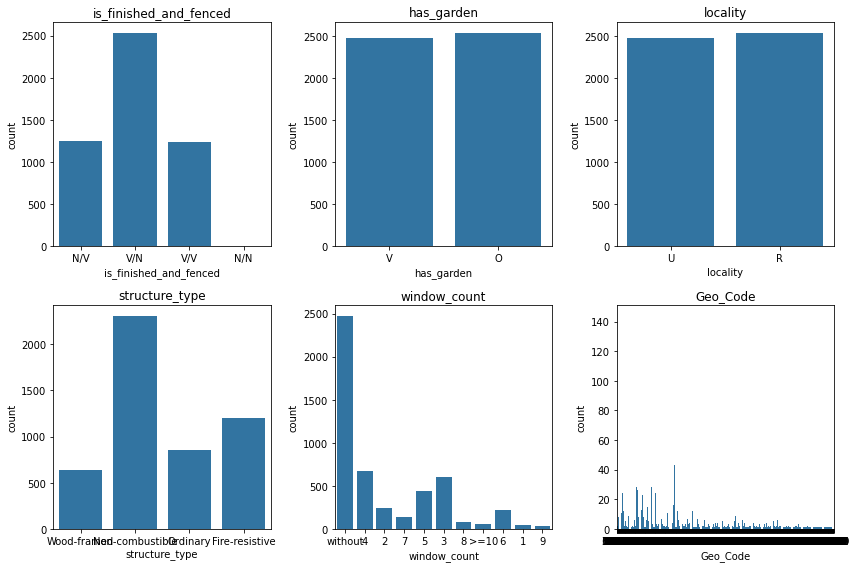

In [50]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(l_discret, start=1):
    plt.subplot(2, 3, i)
    sns.countplot(data=df_train, x=col)
    plt.title(col)

plt.tight_layout()
plt.show()

In [51]:
df_train=pd.get_dummies(df_train, columns=['structure_type'],prefix="",prefix_sep="",dtype='int32')
df_train

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed
0,2012.0,1.0,1.0,N/V,V,U,1240.0,without,75117,0,0,0,0,1
1,2012.0,1.0,0.0,N/V,V,U,900.0,without,62916,0,0,1,0,0
2,2013.0,1.0,1.0,V/N,O,R,4984.0,4,31149,1,0,1,0,0
3,2016.0,0.5,0.0,N/V,V,U,600.0,without,6012,1,0,0,0,1
4,2012.0,1.0,0.0,N/V,V,U,900.0,without,57631,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,N/V,V,U,550.0,without,33063,1,0,0,1,0
5008,2012.0,0.5,0.0,V/N,O,R,1000.0,4,13004,0,1,0,0,0
5009,2015.0,1.0,1.0,V/N,O,R,480.0,3,94059,0,0,0,1,0
5010,2012.0,0.5,0.0,V/N,O,R,536.0,4,74243,0,1,0,0,0


In [52]:
df_test=pd.get_dummies(df_test, columns=['structure_type'],prefix="",prefix_sep="",dtype='int32')
df_test

,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed
0,2013,1.0,0,V/V,V,U,3760.0,without,43157,1,1,0,0,0
1,2015,1.0,0,V/N,O,R,1452.0,5,58194,0,1,0,0,0
2,2013,1.0,1,V/N,O,R,1944.0,6,92050,1,0,0,1,0
3,2015,1.0,0,N/V,V,U,2270.0,without,13209,1,0,1,0,0
4,2016,0.5,0,V/N,O,R,2976.0,9,5177,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,V/N,O,R,862.0,2,6159,0,0,0,0,1
2143,2012,1.0,0,V/V,V,U,1067.0,without,13206,0,0,1,0,0
2144,2014,1.0,0,V/N,O,R,730.0,3,69027,0,0,1,0,0
2145,2014,1.0,1,N/V,V,U,568.0,without,69091,1,0,1,0,0


In [53]:
df_train[['is_finished','fenced']]=df_train['is_finished_and_fenced'].str.split("/", expand=True)
df_train = df_train.drop(columns=["is_finished_and_fenced"])
df_train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2012.0,1.0,1.0,V,U,1240.0,without,75117,0,0,0,0,1,N,V
1,2012.0,1.0,0.0,V,U,900.0,without,62916,0,0,1,0,0,N,V
2,2013.0,1.0,1.0,O,R,4984.0,4,31149,1,0,1,0,0,V,N
3,2016.0,0.5,0.0,V,U,600.0,without,6012,1,0,0,0,1,N,V
4,2012.0,1.0,0.0,V,U,900.0,without,57631,0,0,1,0,0,N,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,V,U,550.0,without,33063,1,0,0,1,0,N,V
5008,2012.0,0.5,0.0,O,R,1000.0,4,13004,0,1,0,0,0,V,N
5009,2015.0,1.0,1.0,O,R,480.0,3,94059,0,0,0,1,0,V,N
5010,2012.0,0.5,0.0,O,R,536.0,4,74243,0,1,0,0,0,V,N


In [54]:
df_test[['is_finished','fenced']]=df_test['is_finished_and_fenced'].str.split("/", expand=True)
df_test = df_test.drop(columns=["is_finished_and_fenced"])
df_test

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2013,1.0,0,V,U,3760.0,without,43157,1,1,0,0,0,V,V
1,2015,1.0,0,O,R,1452.0,5,58194,0,1,0,0,0,V,N
2,2013,1.0,1,O,R,1944.0,6,92050,1,0,0,1,0,V,N
3,2015,1.0,0,V,U,2270.0,without,13209,1,0,1,0,0,N,V
4,2016,0.5,0,O,R,2976.0,9,5177,0,1,0,0,0,V,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,O,R,862.0,2,6159,0,0,0,0,1,V,N
2143,2012,1.0,0,V,U,1067.0,without,13206,0,0,1,0,0,V,V
2144,2014,1.0,0,O,R,730.0,3,69027,0,0,1,0,0,V,N
2145,2014,1.0,1,V,U,568.0,without,69091,1,0,1,0,0,N,V


In [55]:
ord_categories= [["O", "V"],["R","U"],["N", "V"],["N", "V"]]
enc1 = OrdinalEncoder(categories=ord_categories)
df_train[["has_garden","locality","is_finished","fenced"]]=enc1.fit_transform(df_train.loc[:,["has_garden", "locality","is_finished","fenced"]])
df_train["window_count"] = df_train["window_count"].replace({"without":0, ">=10": 10}).astype(int)
df_train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2012.0,1.0,1.0,1.0,1.0,1240.0,0,75117,0,0,0,0,1,0.0,1.0
1,2012.0,1.0,0.0,1.0,1.0,900.0,0,62916,0,0,1,0,0,0.0,1.0
2,2013.0,1.0,1.0,0.0,0.0,4984.0,4,31149,1,0,1,0,0,1.0,0.0
3,2016.0,0.5,0.0,1.0,1.0,600.0,0,6012,1,0,0,0,1,0.0,1.0
4,2012.0,1.0,0.0,1.0,1.0,900.0,0,57631,0,0,1,0,0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1.0,0.0,1.0,1.0,550.0,0,33063,1,0,0,1,0,0.0,1.0
5008,2012.0,0.5,0.0,0.0,0.0,1000.0,4,13004,0,1,0,0,0,1.0,0.0
5009,2015.0,1.0,1.0,0.0,0.0,480.0,3,94059,0,0,0,1,0,1.0,0.0
5010,2012.0,0.5,0.0,0.0,0.0,536.0,4,74243,0,1,0,0,0,1.0,0.0


In [56]:
df_test[["has_garden","locality","is_finished","fenced"]] = (enc1.transform(df_test[["has_garden", "locality","is_finished","fenced"]]))
df_test["window_count"] = df_test["window_count"].replace({"without":0, ">=10": 10}).astype(int)
df_test

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2013,1.0,0,1.0,1.0,3760.0,0,43157,1,1,0,0,0,1.0,1.0
1,2015,1.0,0,0.0,0.0,1452.0,5,58194,0,1,0,0,0,1.0,0.0
2,2013,1.0,1,0.0,0.0,1944.0,6,92050,1,0,0,1,0,1.0,0.0
3,2015,1.0,0,1.0,1.0,2270.0,0,13209,1,0,1,0,0,0.0,1.0
4,2016,0.5,0,0.0,0.0,2976.0,9,5177,0,1,0,0,0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0.5,1,0.0,0.0,862.0,2,6159,0,0,0,0,1,1.0,0.0
2143,2012,1.0,0,1.0,1.0,1067.0,0,13206,0,0,1,0,0,1.0,1.0
2144,2014,1.0,0,0.0,0.0,730.0,3,69027,0,0,1,0,0,1.0,0.0
2145,2014,1.0,1,1.0,1.0,568.0,0,69091,1,0,1,0,0,0.0,1.0


In [57]:
df_train['coverage_period'].unique()

array([1. , 0.5])

In [58]:
df_train["coverage_period"] = df_train["coverage_period"].replace({0.5:0}).astype(int)
df_train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2012.0,1,1.0,1.0,1.0,1240.0,0,75117,0,0,0,0,1,0.0,1.0
1,2012.0,1,0.0,1.0,1.0,900.0,0,62916,0,0,1,0,0,0.0,1.0
2,2013.0,1,1.0,0.0,0.0,4984.0,4,31149,1,0,1,0,0,1.0,0.0
3,2016.0,0,0.0,1.0,1.0,600.0,0,6012,1,0,0,0,1,0.0,1.0
4,2012.0,1,0.0,1.0,1.0,900.0,0,57631,0,0,1,0,0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1,0.0,1.0,1.0,550.0,0,33063,1,0,0,1,0,0.0,1.0
5008,2012.0,0,0.0,0.0,0.0,1000.0,4,13004,0,1,0,0,0,1.0,0.0
5009,2015.0,1,1.0,0.0,0.0,480.0,3,94059,0,0,0,1,0,1.0,0.0
5010,2012.0,0,0.0,0.0,0.0,536.0,4,74243,0,1,0,0,0,1.0,0.0


In [59]:
df_test["coverage_period"] = df_test["coverage_period"].replace({0.5:0}).astype(int)
df_test

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2013,1,0,1.0,1.0,3760.0,0,43157,1,1,0,0,0,1.0,1.0
1,2015,1,0,0.0,0.0,1452.0,5,58194,0,1,0,0,0,1.0,0.0
2,2013,1,1,0.0,0.0,1944.0,6,92050,1,0,0,1,0,1.0,0.0
3,2015,1,0,1.0,1.0,2270.0,0,13209,1,0,1,0,0,0.0,1.0
4,2016,0,0,0.0,0.0,2976.0,9,5177,0,1,0,0,0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0,1,0.0,0.0,862.0,2,6159,0,0,0,0,1,1.0,0.0
2143,2012,1,0,1.0,1.0,1067.0,0,13206,0,0,1,0,0,1.0,1.0
2144,2014,1,0,0.0,0.0,730.0,3,69027,0,0,1,0,0,1.0,0.0
2145,2014,1,1,1.0,1.0,568.0,0,69091,1,0,1,0,0,0.0,1.0


In [60]:
df_train["is_residential"] = df_train["is_residential"].astype(int)

In [61]:
df_test["is_residential"] = df_test["is_residential"].astype(int)

## 9. Outliers and scaling of `area_m2`
IQR capping (limits learned on train), then `RobustScaler`.

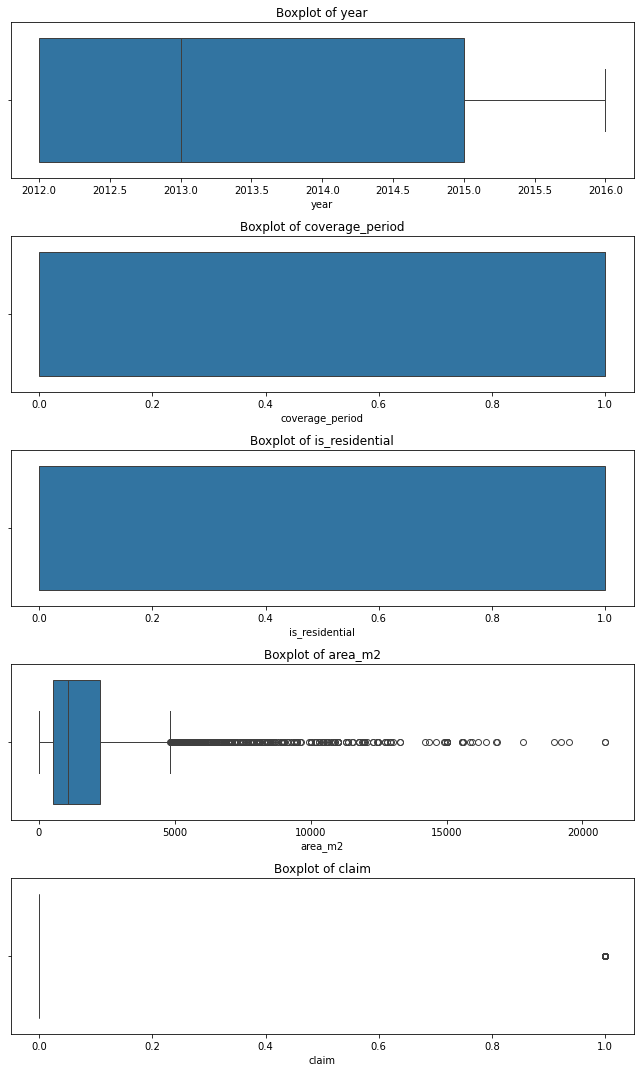

In [62]:
plt.figure(figsize=(9, len(l_num)*3))  

for i, col in enumerate(l_num, 1):
    plt.subplot(len(l_num), 1, i)
    sns.boxplot(x=df_train[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()

plt.show()

In [63]:
Q1, Q3 = np.percentile(df_train["area_m2"], [25, 75])
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

df_train["area_m2"] = np.where(
    df_train["area_m2"] > upper_limit, upper_limit,
    np.where(df_train["area_m2"] < lower_limit, lower_limit, df_train["area_m2"]))

In [64]:
df_test["area_m2"] = np.where(
    df_test["area_m2"] > upper_limit, upper_limit,
    np.where(df_test["area_m2"] < lower_limit, lower_limit, df_test["area_m2"]))

<Axes: xlabel='area_m2'>

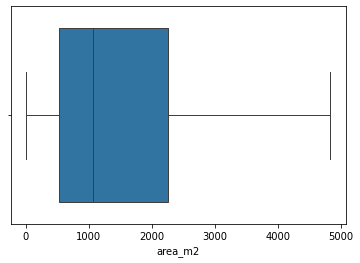

In [65]:
sns.boxplot(x=df_train["area_m2"])

<Axes: xlabel='area_m2'>

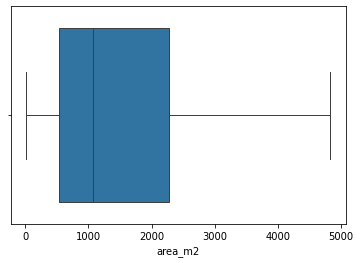

In [66]:
sns.boxplot(x=df_test["area_m2"])

<Axes: xlabel='area_m2', ylabel='Density'>

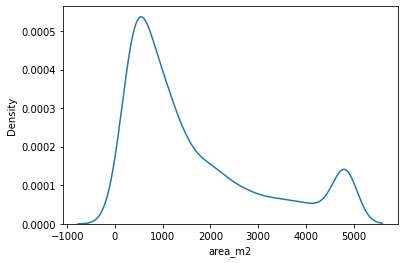

In [68]:
sns.kdeplot(df_train['area_m2'],bw_method='scott', bw_adjust=1)

<Axes: xlabel='area_m2', ylabel='Density'>

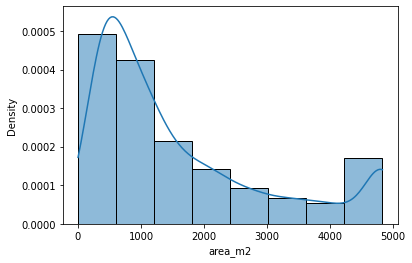

In [69]:
sns.histplot(x="area_m2", data=df_train,bins=8, kde=True, stat='density') 

In [70]:
RobustScaler= RobustScaler()
df_train['area_m2']= RobustScaler.fit_transform(df_train[['area_m2']])
df_train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2012.0,1,1,1.0,1.0,0.100581,0,75117,0,0,0,0,1,0.0,1.0
1,2012.0,1,0,1.0,1.0,-0.097093,0,62916,0,0,1,0,0,0.0,1.0
2,2013.0,1,1,0.0,0.0,2.187791,4,31149,1,0,1,0,0,1.0,0.0
3,2016.0,0,0,1.0,1.0,-0.271512,0,6012,1,0,0,0,1,0.0,1.0
4,2012.0,1,0,1.0,1.0,-0.097093,0,57631,0,0,1,0,0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1,0,1.0,1.0,-0.300581,0,33063,1,0,0,1,0,0.0,1.0
5008,2012.0,0,0,0.0,0.0,-0.038953,4,13004,0,1,0,0,0,1.0,0.0
5009,2015.0,1,1,0.0,0.0,-0.341279,3,94059,0,0,0,1,0,1.0,0.0
5010,2012.0,0,0,0.0,0.0,-0.308721,4,74243,0,1,0,0,0,1.0,0.0


<Axes: xlabel='area_m2', ylabel='Density'>

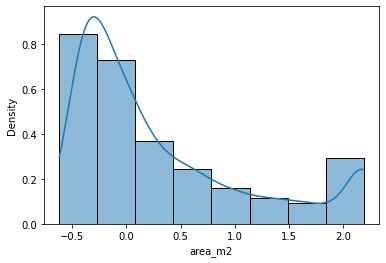

In [71]:
sns.histplot(x="area_m2", data=df_train,bins=8, kde=True, stat='density')

<Axes: xlabel='area_m2', ylabel='Density'>

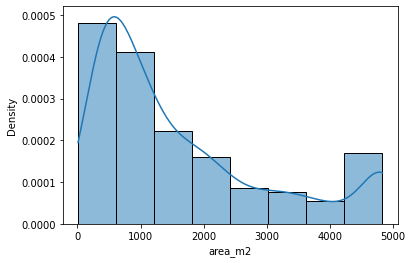

In [72]:
sns.histplot(x="area_m2", data=df_test,bins=8, kde=True, stat='density') 

In [73]:
df_test['area_m2'] = RobustScaler.transform(df_test[['area_m2']])
df_test

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced
0,2013,1,0,1.0,1.0,1.565698,0,43157,1,1,0,0,0,1.0,1.0
1,2015,1,0,0.0,0.0,0.223837,5,58194,0,1,0,0,0,1.0,0.0
2,2013,1,1,0.0,0.0,0.509884,6,92050,1,0,0,1,0,1.0,0.0
3,2015,1,0,1.0,1.0,0.699419,0,13209,1,0,1,0,0,0.0,1.0
4,2016,0,0,0.0,0.0,1.109884,9,5177,0,1,0,0,0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0,1,0.0,0.0,-0.119186,2,6159,0,0,0,0,1,1.0,0.0
2143,2012,1,0,1.0,1.0,0.000000,0,13206,0,0,1,0,0,1.0,1.0
2144,2014,1,0,0.0,0.0,-0.195930,3,69027,0,0,1,0,0,1.0,0.0
2145,2014,1,1,1.0,1.0,-0.290116,0,69091,1,0,1,0,0,0.0,1.0


<Axes: xlabel='area_m2', ylabel='Density'>

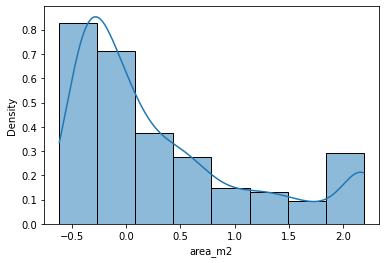

In [74]:
sns.histplot(x="area_m2", data=df_test,bins=8, kde=True, stat='density') 

In [75]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year             5012 non-null   float64
 1   coverage_period  5012 non-null   int32  
 2   is_residential   5012 non-null   int32  
 3   has_garden       5012 non-null   float64
 4   locality         5012 non-null   float64
 5   area_m2          5012 non-null   float64
 6   window_count     5012 non-null   int32  
 7   Geo_Code         5012 non-null   object 
 8   claim            5012 non-null   int32  
 9   Fire-resistive   5012 non-null   int32  
 10  Non-combustible  5012 non-null   int32  
 11  Ordinary         5012 non-null   int32  
 12  Wood-framed      5012 non-null   int32  
 13  is_finished      5012 non-null   float64
 14  fenced           5012 non-null   float64
dtypes: float64(6), int32(8), object(1)
memory usage: 430.8+ KB


## 10. Target encoding of `Geo_Code`
Smoothed mean of `claim` per geographic code, computed **out-of-fold** on the training set.

In [76]:
# Target encoding of Geo_Code with smoothing.
# Train: out-of-fold encoding (5 folds) so that a row never sees its own label -> no target leakage.
# Test: encoding learned on the whole training set.
from sklearn.model_selection import KFold

smoothing = 10
global_mean = df_train['claim'].mean()

def smoothed_means(df):
    stats = df.groupby('Geo_Code')['claim'].agg(['mean', 'count'])
    return (stats['mean'] * stats['count'] + global_mean * smoothing) / (stats['count'] + smoothing)

df_train['Geo_Code_TE'] = global_mean
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for fit_idx, enc_idx in kf.split(df_train):
    te = smoothed_means(df_train.iloc[fit_idx])
    df_train.loc[df_train.index[enc_idx], 'Geo_Code_TE'] = (
        df_train.iloc[enc_idx]['Geo_Code'].map(te).fillna(global_mean).values)

df_test['Geo_Code_TE'] = df_test['Geo_Code'].map(smoothed_means(df_train)).fillna(global_mean)

df_train = df_train.drop(columns=["Geo_Code"])
df_test = df_test.drop(columns=["Geo_Code"])

In [77]:
df_train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced,Geo_Code_TE
0,2012.0,1,1,1.0,1.0,0.100581,0,0,0,0,0,1,0.0,1.0,0.264189
1,2012.0,1,0,1.0,1.0,-0.097093,0,0,0,1,0,0,0.0,1.0,0.187217
2,2013.0,1,1,0.0,0.0,2.187791,4,1,0,1,0,0,1.0,0.0,0.224661
3,2016.0,0,0,1.0,1.0,-0.271512,0,1,0,0,0,1,0.0,1.0,0.284366
4,2012.0,1,0,1.0,1.0,-0.097093,0,0,0,1,0,0,0.0,1.0,0.204237
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1,0,1.0,1.0,-0.300581,0,1,0,0,1,0,0.0,1.0,0.193973
5008,2012.0,0,0,0.0,0.0,-0.038953,4,0,1,0,0,0,1.0,0.0,0.201793
5009,2015.0,1,1,0.0,0.0,-0.341279,3,0,0,0,1,0,1.0,0.0,0.224661
5010,2012.0,0,0,0.0,0.0,-0.308721,4,0,1,0,0,0,1.0,0.0,0.172816


In [78]:
df_test

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,claim,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced,Geo_Code_TE
0,2013,1,0,1.0,1.0,1.565698,0,1,1,0,0,0,1.0,1.0,0.260275
1,2015,1,0,0.0,0.0,0.223837,5,0,1,0,0,0,1.0,0.0,0.209864
2,2013,1,1,0.0,0.0,0.509884,6,1,0,0,1,0,1.0,0.0,0.180367
3,2015,1,0,1.0,1.0,0.699419,0,1,0,1,0,0,0.0,1.0,0.154312
4,2016,0,0,0.0,0.0,1.109884,9,0,1,0,0,0,1.0,0.0,0.132153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0,1,0.0,0.0,-0.119186,2,0,0,0,0,1,1.0,0.0,0.291478
2143,2012,1,0,1.0,1.0,0.000000,0,0,0,1,0,0,1.0,1.0,0.187469
2144,2014,1,0,0.0,0.0,-0.195930,3,0,0,1,0,0,1.0,0.0,0.224661
2145,2014,1,1,1.0,1.0,-0.290116,0,1,0,1,0,0,0.0,1.0,0.106981


## 11. Features / target split

In [79]:
y_train= df_train["claim"]
df_train=df_train.drop(columns=["claim"])
y_train

0       0
1       0
2       1
3       1
4       0
       ..
5007    1
5008    0
5009    0
5010    0
5011    0
Name: claim, Length: 5012, dtype: int32

In [80]:
y_test= df_test["claim"]
df_test=df_test.drop(columns=["claim"])
y_test

0       1
1       0
2       1
3       1
4       0
       ..
2142    0
2143    0
2144    0
2145    1
2146    0
Name: claim, Length: 2147, dtype: int32

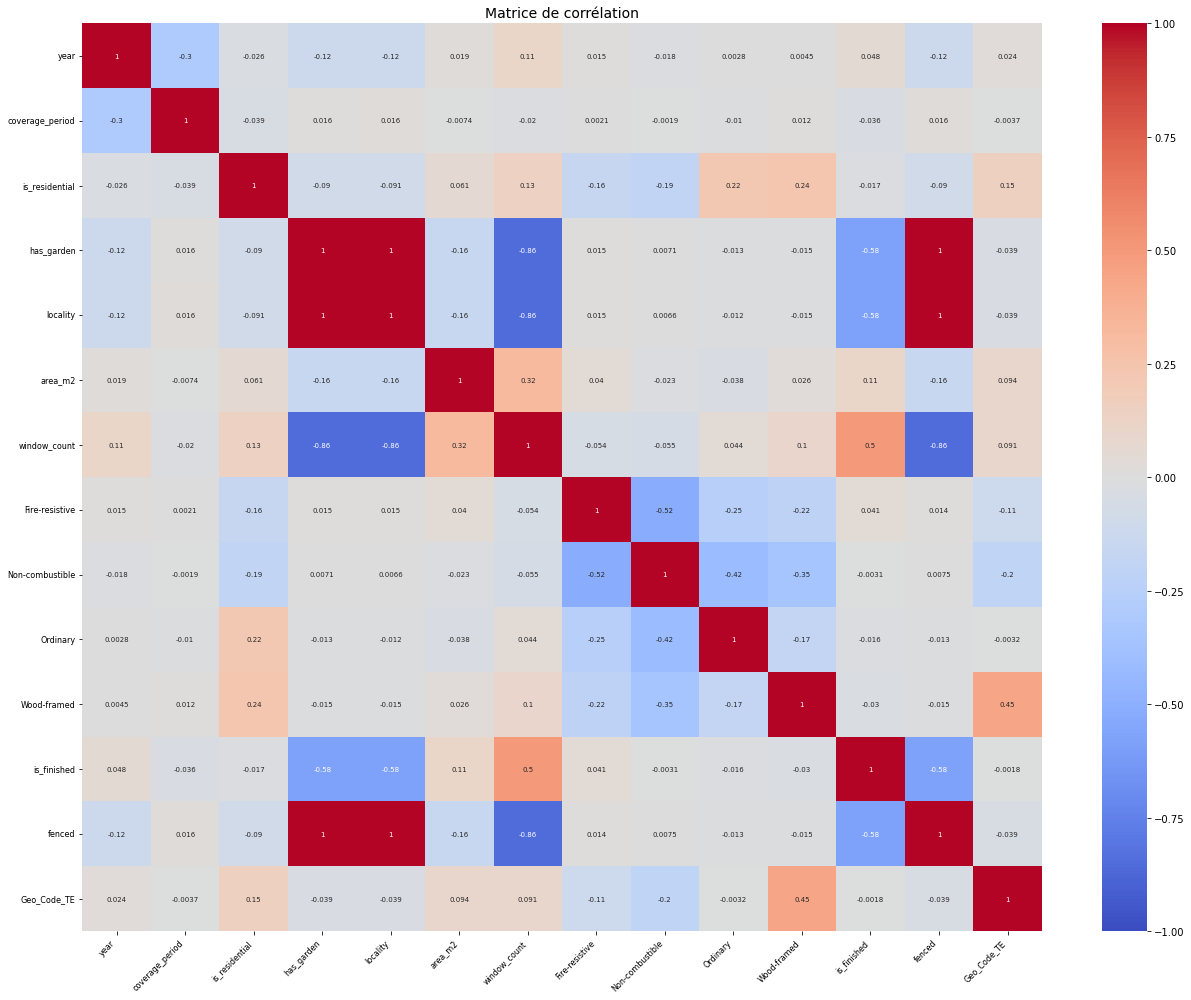

In [81]:
df_corr=df_train.corr(numeric_only= True)
plt.figure(figsize=(18, 14))
sns.heatmap(df_corr,annot=True,vmin=-1, vmax=1,cmap="coolwarm",annot_kws={"size": 7})
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.title("Matrice de corrélation", fontsize=14)
plt.tight_layout()
plt.show()

## 12. Association rules (Apriori)
Frequent itemsets on the binary variables; the strong rules justify merging `fenced`, `has_garden` and `locality` into one synthetic feature **`LFG`**.

In [82]:
binary_cols = ['has_garden','locality','is_finished','fenced']
df_train[binary_cols]=df_train[binary_cols].astype(int)
df_train[binary_cols]

,has_garden,locality,is_finished,fenced
0,1,1,0,1
1,1,1,0,1
2,0,0,1,0
3,1,1,0,1
4,1,1,0,1
...,...,...,...,...
5007,1,1,0,1
5008,0,0,1,0
5009,0,0,1,0
5010,0,0,1,0


In [83]:
df_test[binary_cols]=df_test[binary_cols].astype(int)
df_test[binary_cols]

,has_garden,locality,is_finished,fenced
0,1,1,1,1
1,0,0,1,0
2,0,0,1,0
3,1,1,0,1
4,0,0,1,0
...,...,...,...,...
2142,0,0,1,0
2143,1,1,1,1
2144,0,0,1,0
2145,1,1,0,1


In [84]:
df_train_binary = df_train[binary_cols]
df_train_binary

,has_garden,locality,is_finished,fenced
0,1,1,0,1
1,1,1,0,1
2,0,0,1,0
3,1,1,0,1
4,1,1,0,1
...,...,...,...,...
5007,1,1,0,1
5008,0,0,1,0
5009,0,0,1,0
5010,0,0,1,0


In [85]:
df_test_binary = df_test[binary_cols]
df_test_binary

,has_garden,locality,is_finished,fenced
0,1,1,1,1
1,0,0,1,0
2,0,0,1,0
3,1,1,0,1
4,0,0,1,0
...,...,...,...,...
2142,0,0,1,0
2143,1,1,1,1
2144,0,0,1,0
2145,1,1,0,1


In [86]:
freq_items1= apriori(df_train_binary, min_support=0.1,use_colnames=True)
freq_items1

,support,itemsets
0,0.494014,(has_garden)
1,0.493815,(locality)
2,0.750798,(is_finished)
3,0.494214,(fenced)
4,0.493815,"(locality, has_garden)"
5,0.245810,"(is_finished, has_garden)"
6,0.494014,"(has_garden, fenced)"
7,0.245611,"(is_finished, locality)"
8,0.493815,"(locality, fenced)"
9,0.246010,"(is_finished, fenced)"


In [87]:
len(freq_items1[(freq_items1['itemsets'].gt({'is_finished'}))])

7

In [88]:
rules_p= association_rules(freq_items1, metric="confidence",min_threshold=0.5)
rules_p

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(locality),(has_garden),0.493815,0.494014,0.493815,1.000000,2.024233,1.0,0.249863,inf,0.999606,0.999596,1.000000,0.999798
1,(has_garden),(locality),0.494014,0.493815,0.493815,0.999596,2.024233,1.0,0.249863,1253.314445,1.000000,0.999596,0.999202,0.999798
2,(has_garden),(fenced),0.494014,0.494214,0.494014,1.000000,2.023415,1.0,0.249866,inf,0.999606,0.999596,1.000000,0.999798
3,(fenced),(has_garden),0.494214,0.494014,0.494014,0.999596,2.023415,1.0,0.249866,1253.326417,1.000000,0.999596,0.999202,0.999798
4,(locality),(fenced),0.493815,0.494214,0.493815,1.000000,2.023415,1.0,0.249765,inf,0.999212,0.999193,1.000000,0.999596
5,(fenced),(locality),0.494214,0.493815,0.493815,0.999193,2.023415,1.0,0.249765,626.910315,1.000000,0.999193,0.998405,0.999596
6,"(is_finished, locality)",(has_garden),0.245611,0.494014,0.245611,1.000000,2.024233,1.0,0.124275,inf,0.670722,0.497173,1.000000,0.748586
7,"(is_finished, has_garden)",(locality),0.245810,0.493815,0.245611,0.999188,2.023407,1.0,0.124226,623.620112,0.670632,0.497173,0.998396,0.748281
8,"(locality, has_garden)",(fenced),0.493815,0.494214,0.493815,1.000000,2.023415,1.0,0.249765,inf,0.999212,0.999193,1.000000,0.999596
9,"(locality, fenced)",(has_garden),0.493815,0.494014,0.493815,1.000000,2.024233,1.0,0.249863,inf,0.999606,0.999596,1.000000,0.999798


In [89]:
rules_lift = rules_p[(rules_p['leverage'] > 0) & (rules_p['conviction'] > 1) & (rules_p['lift'] > 1) & (rules_p['confidence'] > 0.3)]
rules_lift

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(locality),(has_garden),0.493815,0.494014,0.493815,1.000000,2.024233,1.0,0.249863,inf,0.999606,0.999596,1.000000,0.999798
1,(has_garden),(locality),0.494014,0.493815,0.493815,0.999596,2.024233,1.0,0.249863,1253.314445,1.000000,0.999596,0.999202,0.999798
2,(has_garden),(fenced),0.494014,0.494214,0.494014,1.000000,2.023415,1.0,0.249866,inf,0.999606,0.999596,1.000000,0.999798
3,(fenced),(has_garden),0.494214,0.494014,0.494014,0.999596,2.023415,1.0,0.249866,1253.326417,1.000000,0.999596,0.999202,0.999798
4,(locality),(fenced),0.493815,0.494214,0.493815,1.000000,2.023415,1.0,0.249765,inf,0.999212,0.999193,1.000000,0.999596
5,(fenced),(locality),0.494214,0.493815,0.493815,0.999193,2.023415,1.0,0.249765,626.910315,1.000000,0.999193,0.998405,0.999596
6,"(is_finished, locality)",(has_garden),0.245611,0.494014,0.245611,1.000000,2.024233,1.0,0.124275,inf,0.670722,0.497173,1.000000,0.748586
7,"(is_finished, has_garden)",(locality),0.245810,0.493815,0.245611,0.999188,2.023407,1.0,0.124226,623.620112,0.670632,0.497173,0.998396,0.748281
8,"(locality, has_garden)",(fenced),0.493815,0.494214,0.493815,1.000000,2.023415,1.0,0.249765,inf,0.999212,0.999193,1.000000,0.999596
9,"(locality, fenced)",(has_garden),0.493815,0.494014,0.493815,1.000000,2.024233,1.0,0.249863,inf,0.999606,0.999596,1.000000,0.999798


In [90]:
df_train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,fenced,Geo_Code_TE
0,2012.0,1,1,1,1,0.100581,0,0,0,0,1,0,1,0.264189
1,2012.0,1,0,1,1,-0.097093,0,0,1,0,0,0,1,0.187217
2,2013.0,1,1,0,0,2.187791,4,0,1,0,0,1,0,0.224661
3,2016.0,0,0,1,1,-0.271512,0,0,0,0,1,0,1,0.284366
4,2012.0,1,0,1,1,-0.097093,0,0,1,0,0,0,1,0.204237
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1,0,1,1,-0.300581,0,0,0,1,0,0,1,0.193973
5008,2012.0,0,0,0,0,-0.038953,4,1,0,0,0,1,0,0.201793
5009,2015.0,1,1,0,0,-0.341279,3,0,0,1,0,1,0,0.224661
5010,2012.0,0,0,0,0,-0.308721,4,1,0,0,0,1,0,0.172816


In [91]:
df_train['LFG']= df_train['fenced'] & df_train['has_garden'] & df_train['locality']
df_train.drop(columns=['fenced'], inplace=True)
df_train.drop(columns=['has_garden'], inplace=True)
df_train.drop(columns=['locality'], inplace=True)

In [92]:
df_train

,year,coverage_period,is_residential,area_m2,window_count,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,Geo_Code_TE,LFG
0,2012.0,1,1,0.100581,0,0,0,0,1,0,0.264189,1
1,2012.0,1,0,-0.097093,0,0,1,0,0,0,0.187217,1
2,2013.0,1,1,2.187791,4,0,1,0,0,1,0.224661,0
3,2016.0,0,0,-0.271512,0,0,0,0,1,0,0.284366,1
4,2012.0,1,0,-0.097093,0,0,1,0,0,0,0.204237,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5007,2013.0,1,0,-0.300581,0,0,0,1,0,0,0.193973,1
5008,2012.0,0,0,-0.038953,4,1,0,0,0,1,0.201793,0
5009,2015.0,1,1,-0.341279,3,0,0,1,0,1,0.224661,0
5010,2012.0,0,0,-0.308721,4,1,0,0,0,1,0.172816,0


In [93]:
df_test['LFG']= df_test['fenced'] & df_test['has_garden'] & df_test['locality']
df_test.drop(columns=['fenced'], inplace=True)
df_test.drop(columns=['has_garden'], inplace=True)
df_test.drop(columns=['locality'], inplace=True)

In [94]:
df_test

,year,coverage_period,is_residential,area_m2,window_count,Fire-resistive,Non-combustible,Ordinary,Wood-framed,is_finished,Geo_Code_TE,LFG
0,2013,1,0,1.565698,0,1,0,0,0,1,0.260275,1
1,2015,1,0,0.223837,5,1,0,0,0,1,0.209864,0
2,2013,1,1,0.509884,6,0,0,1,0,1,0.180367,0
3,2015,1,0,0.699419,0,0,1,0,0,0,0.154312,1
4,2016,0,0,1.109884,9,1,0,0,0,1,0.132153,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,0,1,-0.119186,2,0,0,0,1,1,0.291478,0
2143,2012,1,0,0.000000,0,0,1,0,0,1,0.187469,1
2144,2014,1,0,-0.195930,3,0,1,0,0,1,0.224661,0
2145,2014,1,1,-0.290116,0,0,1,0,0,0,0.106981,1


## 13. Model 1 — Decision Tree
Interpretable baseline (`max_depth=4`, `class_weight='balanced'` because of class imbalance).

In [95]:
dt_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    min_samples_split=30,
    min_samples_leaf=15,
    class_weight="balanced",
    random_state=42
)
dt_model.fit(df_train, y_train)

DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=4, min_samples_leaf=15, min_samples_split=30,
                       random_state=42)

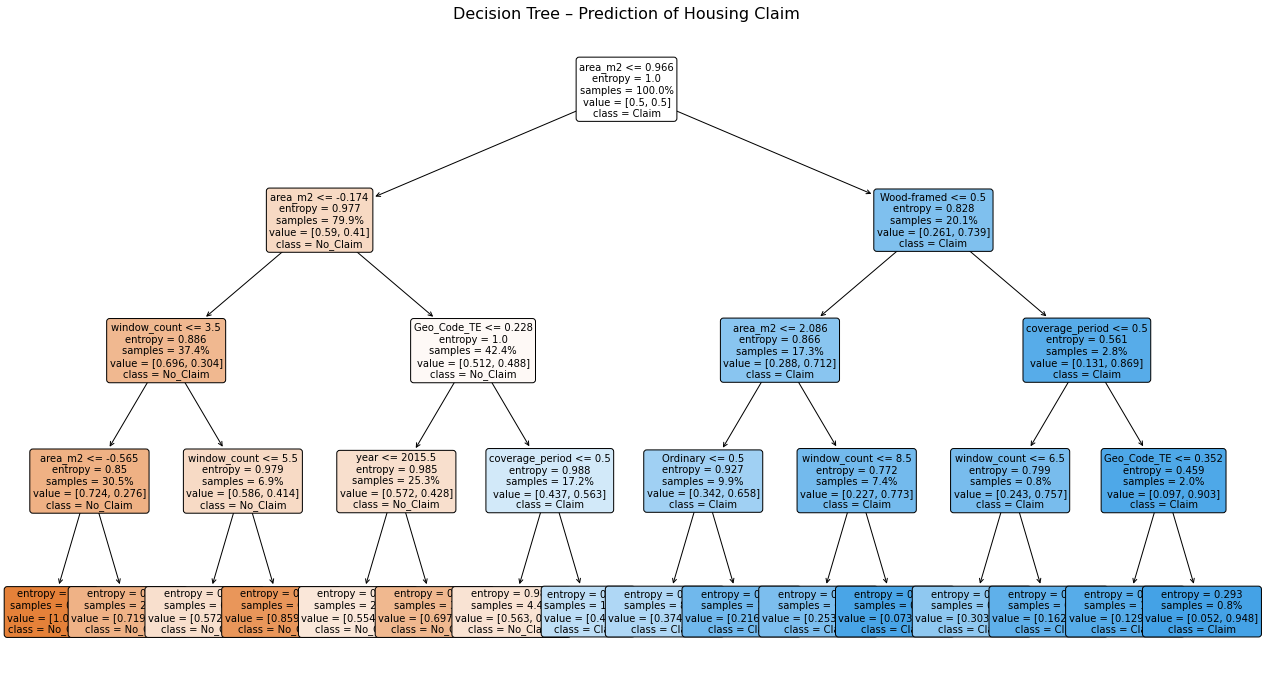

In [96]:
plt.figure(figsize=(22, 12))  

plot_tree(
    dt_model,
    feature_names=list(df_train),
    class_names=["No_Claim", "Claim"],
    filled=True,
    rounded=True,
    fontsize=10,        # taille du texte
    proportion=True     # montre les proportions au lieu des comptes
)

plt.title("Decision Tree – Prediction of Housing Claim", fontsize=16)
plt.show()


In [97]:
y_pred_tr = dt_model.predict(df_train)
y_pred_test = dt_model.predict(df_test)

print("acc_train=",np.round( accuracy_score(y_train, y_pred_tr),2))
print("acc_test=",np.round( accuracy_score(y_test, y_pred_test),2))
print("f1_train=",np.round(f1_score(y_train, y_pred_tr, average='weighted'),2))
print("f1_test=",np.round(f1_score(y_test, y_pred_test, average='weighted'),2))

acc_train= 0.71
acc_test= 0.7
f1_train= 0.72
f1_test= 0.72


In [98]:
dt_model.classes_ 

array([0, 1])

AUC = 0.698890960014989


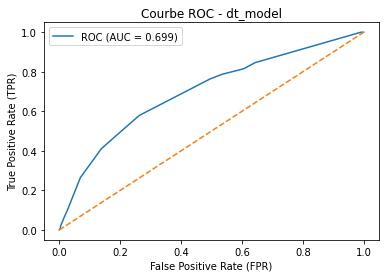

In [99]:
y_prob=dt_model.predict_proba(df_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob,pos_label=1)
roc_auc = roc_auc_score(y_test, y_prob)
print("AUC =", roc_auc)
plt.figure()
plt.plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--') 
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Courbe ROC - dt_model")
plt.legend()
plt.show()

In [100]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.85      0.74      0.79      1639
           1       0.41      0.58      0.48       508

    accuracy                           0.70      2147
   macro avg       0.63      0.66      0.63      2147
weighted avg       0.74      0.70      0.72      2147



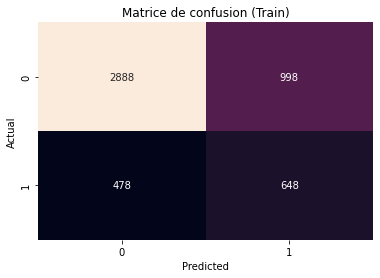

In [101]:
Y_p_train=dt_model.predict(df_train)
c_m_train=confusion_matrix(y_train, Y_p_train)
sns.heatmap(c_m_train, annot=True, cbar=False,fmt="d", xticklabels=dt_model.classes_, yticklabels=dt_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title('Matrice de confusion (Train)')
plt.show()


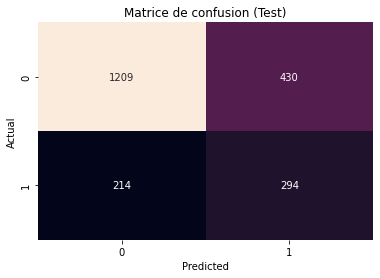

In [102]:
Y_p_test=dt_model.predict(df_test)
c_m_test=confusion_matrix(y_test, Y_p_test)
sns.heatmap(c_m_test, annot=True, cbar=False,fmt="d", xticklabels=dt_model.classes_, yticklabels=dt_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title('Matrice de confusion (Test)')
plt.show()

## 14. Model 2 — Random Forest
Out-of-bag score and OOB error as a function of the number of trees.

In [103]:
rf_model = RandomForestClassifier(
    n_estimators=300,          # nombre d’arbres
    max_depth=10,              # limite le sur-apprentissage
    min_samples_leaf=10,       # protège la classe minoritaire
    class_weight="balanced",   # essentiel pour le déséquilibre
    random_state=42,
    oob_score=True
)
rf_model.fit(df_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=10, n_estimators=300, oob_score=True,
                       random_state=42)

In [104]:
rf_model.oob_score_

0.7116919393455706

In [105]:
y_pred_rf = rf_model.predict(df_test)
print(classification_report(y_test, y_pred_rf))


              precision    recall  f1-score   support

           0       0.84      0.77      0.80      1639
           1       0.42      0.55      0.47       508

    accuracy                           0.71      2147
   macro avg       0.63      0.66      0.64      2147
weighted avg       0.74      0.71      0.73      2147



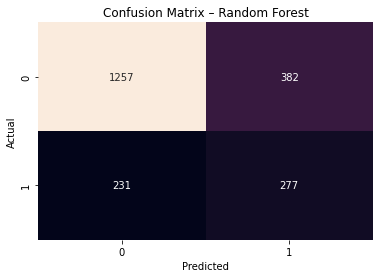

In [106]:
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, cbar=False,fmt="d",
xticklabels=rf_model.classes_, yticklabels=rf_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Random Forest")
plt.show()


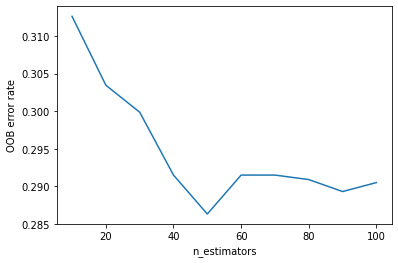

In [107]:
def oob_error(nbT):
    rf_model.set_params(n_estimators=nbT)
    rf_model.fit(df_train,y_train)
    return 1-rf_model.oob_score_
n_estimators=list(range(10,101,10))
oob_errors=list(map(oob_error,n_estimators))
plt.plot(n_estimators,oob_errors)
plt.xlabel("n_estimators")
plt.ylabel("OOB error rate")
plt.show()

## 15. Hyperparameter tuning — RandomizedSearchCV
Scoring = **recall** on the claim class (missing a claim is the costly error).

In [108]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15],
    "min_samples_leaf": [5, 10, 20],
    "min_samples_split": [10, 20, 30],
    "max_features": ["sqrt", "log2"]
}


random_search = RandomizedSearchCV(
    rf_model,
    param_distributions=param_dist,
    n_iter=30,              # nombre de combinaisons testées
    scoring="recall",       # priorité au sinistre
    cv=5,
    verbose=1,
    random_state=42
)

random_search.fit(df_train, y_train)
print(random_search.best_params_)
print(random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 20, 'max_features': 'log2', 'max_depth': None}
0.5657423795476892


In [109]:
importances = random_search.best_estimator_.feature_importances_
importance_df = pd.DataFrame({'Feature':list(df_train),'Importance':importances})
importance_df = importance_df.sort_values(by='Importance',ascending=False)
importance_df.head(10)

,Feature,Importance
3,area_m2,0.484650
10,Geo_Code_TE,0.165880
4,window_count,0.131468
0,year,0.053812
1,coverage_period,0.031992
8,Wood-framed,0.031591
5,Fire-resistive,0.021086
11,LFG,0.019061
2,is_residential,0.018678
6,Non-combustible,0.015653


## 16. Final evaluation
Top-10 features, 10-fold cross-validation on train, then one single evaluation of the tuned model on the test set.

In [110]:
# Keep the 10 most important features and estimate performance with 10-fold cross-validation on the TRAIN set
from sklearn.base import clone
features = importance_df.head(10).loc[:, 'Feature'].to_list()
best_rf = clone(random_search.best_estimator_)
y_pred_cv = cross_val_predict(best_rf, df_train[features], y_train, cv=10)
print(classification_report(y_train, y_pred_cv))

              precision    recall  f1-score   support

           0       0.85      0.74      0.79      3886
           1       0.38      0.56      0.45      1126

    accuracy                           0.70      5012
   macro avg       0.62      0.65      0.62      5012
weighted avg       0.75      0.70      0.72      5012



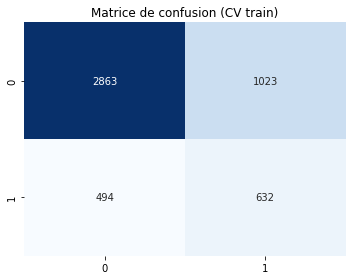

In [111]:
labels = rf_model.classes_ 

cm = confusion_matrix(y_train, y_pred_cv, labels=labels) 

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Matrice de confusion (CV train)")
plt.tight_layout()
plt.show()

In [112]:
# Final model: trained on the whole training set, evaluated ONCE on the test set
best_rf.fit(df_train[features], y_train)
y_pred = best_rf.predict(df_test[features])
y_prob_rf = best_rf.predict_proba(df_test[features])[:, 1]
print(classification_report(y_test, y_pred))
print("AUC =", round(roc_auc_score(y_test, y_prob_rf), 3))

              precision    recall  f1-score   support

           0       0.86      0.74      0.79      1639
           1       0.41      0.60      0.49       508

    accuracy                           0.70      2147
   macro avg       0.64      0.67      0.64      2147
weighted avg       0.75      0.70      0.72      2147

AUC = 0.716


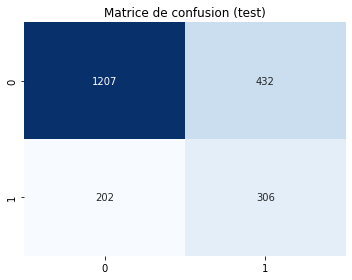

In [113]:
labels = rf_model.classes_ 

cm = confusion_matrix(y_test, y_pred, labels=labels) 

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Matrice de confusion (test)")
plt.tight_layout()
plt.show()